### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
data = pd.read_csv('data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
#First we see if any columns are missing any values. However, if a column is not missing values, it doesn't meant it doesn't contain problematic data.
missing_values=data.isnull().sum()
print(missing_values)
#To compare the number of missing info to the total enteries, we find the size of the sample.
print(data.shape)
#Let's also take a look at how some of the numberic info such as age is entered
data["age"].value_counts()

destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64
(12684, 26)


From the results, looks like column "car" is missing most of the information and therefore will not be very useful.
Looks like there are many numerical information such as income or age that are nor entered as integers. They include characterers other than numbers and data type other than integer. We'll bear this in mind as we carry out the data investigation and analysis.

3. Decide what to do about your missing data -- drop, replace, other...

In [40]:
#Looks like 6 of the columns contain missing data. Let's Look furthere into these columns.
data["car"].value_counts()
data["Bar"].value_counts()
data["CoffeeHouse"].value_counts()
data["CarryAway"].value_counts()

time
6PM     3230
7AM     3164
10AM    2275
2PM     2009
10PM    2006
Name: count, dtype: int64

At this moment there is no useful information to replace the missing data with. To get the most information from the data provided, keep the data as is at this time. We Will drop the missing data as needed in different sections.

4. What proportion of the total observations chose to accept the coupon?



In [35]:
Accepted_Quanity = data["Y"].sum()
Sample_Size = data.shape[0]
Portion_Accepted = Accepted_Quanity/Sample_Size

print(Portion_Accepted)


0.5684326710816777


5. Use a bar plot to visualize the `coupon` column.

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'Coffee House'),
  Text(1, 0, 'Restaurant(<20)'),
  Text(2, 0, 'Carry out & Take away'),
  Text(3, 0, 'Bar'),
  Text(4, 0, 'Restaurant(20-50)')])

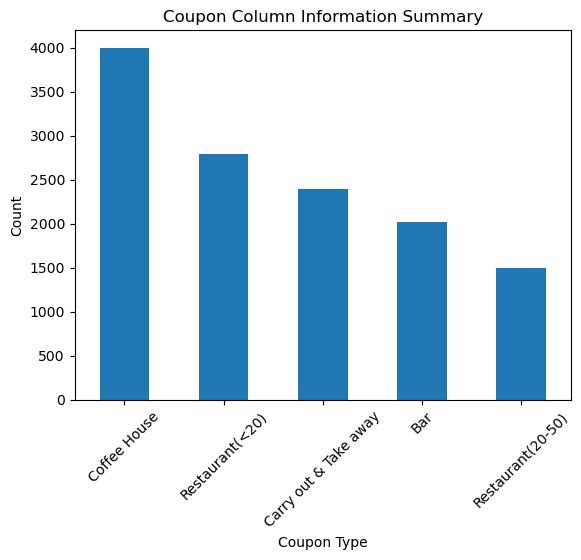

In [7]:
data["coupon"].value_counts().plot(kind="bar")

plt.title('Coupon Column Information Summary')
plt.xlabel('Coupon Type')
plt.ylabel('Count')
plt.xticks(rotation=45)


6. Use a histogram to visualize the temperature column.

([<matplotlib.axis.XTick at 0x18feb7082d0>,
 [Text(30, 0, '30'), Text(55, 0, '55'), Text(80, 0, '80')])

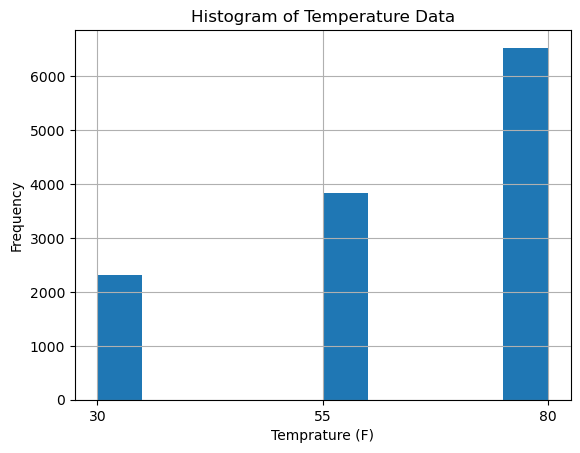

In [8]:
data["temperature"].hist()
plt.title('Histogram of Temperature Data')
plt.xlabel('Temprature (F)')
plt.ylabel('Frequency')
plt.xticks([30, 55, 80])

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [9]:
bar_Coupon = pd.DataFrame(data)
bar_Coupon = data.query('coupon == "Bar"')
print(bar_Coupon)


           destination  passanger weather  temperature  time coupon  \
9      No Urgent Place     Kid(s)   Sunny           80  10AM    Bar   
13                Home      Alone   Sunny           55   6PM    Bar   
17                Work      Alone   Sunny           55   7AM    Bar   
24     No Urgent Place  Friend(s)   Sunny           80  10AM    Bar   
35                Home      Alone   Sunny           55   6PM    Bar   
...                ...        ...     ...          ...   ...    ...   
12663  No Urgent Place  Friend(s)   Sunny           80  10PM    Bar   
12664  No Urgent Place  Friend(s)   Sunny           55  10PM    Bar   
12667  No Urgent Place      Alone   Rainy           55  10AM    Bar   
12670  No Urgent Place    Partner   Rainy           55   6PM    Bar   
12682             Work      Alone   Snowy           30   7AM    Bar   

      expiration  gender age      maritalStatus  ...  CoffeeHouse CarryAway  \
9             1d  Female  21  Unmarried partner  ...        never   

2. What proportion of bar coupons were accepted?


In [10]:
#We know that column "Y" and "coupon" have no missing entries.
Bar_Coupon_Accepted = bar_Coupon["Y"].sum()
Total_Bar_Coupons = bar_Coupon.shape[0]
Portion_Bar_Coupon_Accepted = Bar_Coupon_Accepted / Total_Bar_Coupons
print(Portion_Bar_Coupon_Accepted )

0.41001487357461575


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [11]:
#For this question, we drop the rows with missing values in the "Bar" column so that the number of rows equal the 
#total number of data we have on this topic
bar_Coupon.dropna(subset=['Bar'])
High_Frequent = ["4~8" , "gt8"]
Low_Frequent = ["never","less1","1~3"]
Bar_Coupon_High_Freq = bar_Coupon.query('Bar in @ High_Frequent')["Y"].sum()
Bar_Coupon_Low_Freq = bar_Coupon.query('Bar in @ Low_Frequent')["Y"].sum()
#Compare the number of people who accepeted the bar coupon and went to bar 3 or fewer times/month to those who went more
Accept_Ratio = Bar_Coupon_Low_Freq/Bar_Coupon_High_Freq
#Calculate the acceptance percentage of those who went to a bar more than 3 times/month and accepted the bar coupon
Bar_High_Frq_Accept_Prc = Bar_Coupon_High_Freq / (Bar_Coupon_High_Freq+Bar_Coupon_Low_Freq)
#Calculate the acceptance percentage of those who went to a bar 3 or fewer times/month and accepted the bar coupon
Bar_Low_Frq_Accept_Prc = Bar_Coupon_Low_Freq / (Bar_Coupon_High_Freq+Bar_Coupon_Low_Freq)
#print(Bar_Coupon_High_Freq,Bar_Coupon_Low_Freq, Bar_Coupon_Accepted)
print(Accept_Ratio,Bar_High_Frq_Accept_Prc, Bar_Low_Frq_Accept_Prc )
#People who went to bars less frequently (3 or fewer times a month) are significantly more likely to accept the coupon 
#compare to those who went to bar more than 3 times/month.

4.352941176470588 0.18681318681318682 0.8131868131868132


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [58]:
#Define the values in each column we are interested or want to exclude
Freq1 = ["never" , "less1"]
Ba = bar_Coupon.query('Bar not in @Freq1')
bar_Coupon["age"].value_counts()
#For the purposes of this question, we are replacing the upperbound and lower bound of the age groups with a single value so that we can use easier 
#when invetigating people younger or older than a certain age. We will only do this adjustment on a copy of the data frame.
Ba["age"] = Ba["age"].str.replace("50plus", "50").replace("below21","20")
Ba["age"].value_counts()
#convert the data type to integer
Ba["age"] = Ba["age"].astype(int)
#check that data tyope of column age is integer
Ba["age"].info()
#Calculate the number of people who satisfy the requirements
B2 = Ba.query('age > 25')["Y"].sum()
result = B2/Bar_Coupon_Accepted
Prc4 = B2/Total_Bar_Coupons
print(result, Prc4)

<class 'pandas.core.series.Series'>
Index: 617 entries, 90 to 12544
Series name: age
Non-Null Count  Dtype
--------------  -----
617 non-null    int64
dtypes: int64(1)
memory usage: 9.6 KB
0.36275695284159615 0.1487357461576599


C:\Users\hzr18\AppData\Local\Temp\ipykernel_20456\1940812194.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Ba["age"] = Ba["age"].str.replace("50plus", "50").replace("below21","20")
C:\Users\hzr18\AppData\Local\Temp\ipykernel_20456\1940812194.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Ba["age"] = Ba["age"].astype(int)


Only about %36 of those who accepted the bar coupon were over the age of 25 and when to bar more than once a month.
Since those who accepted the bar coupon were more likely to go to a bar at most once a month, it is interesting to know how many of those were over the age of 25.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [13]:
#Let's look into the data first to see how the data is categorized
data["passanger"].value_counts()
data["occupation"].value_counts()

occupation
Unemployed                                   1870
Student                                      1584
Computer & Mathematical                      1408
Sales & Related                              1093
Education&Training&Library                    943
Management                                    838
Office & Administrative Support               639
Arts Design Entertainment Sports & Media      629
Business & Financial                          544
Retired                                       495
Food Preparation & Serving Related            298
Healthcare Practitioners & Technical          244
Healthcare Support                            242
Community & Social Services                   241
Legal                                         219
Transportation & Material Moving              218
Architecture & Engineering                    175
Personal Care & Service                       175
Protective Service                            175
Life Physical Social Science           

In [ ]:
data["occupation"].value_counts()

In [50]:
#Define the values in each column we are interested or want to exclude
Freq5= ['1~3', '4-8', 'gt8']
passanger5 = ["Friend(s)", "Partner"]
#Please note the question state "had occupation ..." therefore, it is assumed that the interested group doesn't include unemployed, students, or retired groups.
#since there is only a single occupation we are excluding, we will use "not in"
occupation5 = ["Unemployed","Students","Retired","Farming Fishing & Forestry"]
#First let's a take a look at the number of people who satisfy each of the categories seperately for comparison
Bb5 = bar_Coupon.query('Bar in @Freq5')["Y"].sum()
Bp5 = bar_Coupon.query('passanger in @passanger5')["Y"].sum()
Bo5 = bar_Coupon.query('occupation not in @occupation5')["Y"].sum()
#Calculate the percentages accordingly
Pb5 = Bb5/Total_Bar_Coupons
Pp5 = Bp5/Total_Bar_Coupons
Po5 = Bo5/Total_Bar_Coupons
#Calculate the number of people who stisfy all of the requirements above
B5 = bar_Coupon.query('Bar in @Freq5 and passanger in @passanger5 and occupation not in @occupation5')["Y"].sum()
#Calculate the percentages of people who were given a bar coupon and satisfied the requirement of the question prompt
perc5a = B5/Total_Bar_Coupons
#Calculate the percentages of people who accepted bar coupon and satisfied the requirement of the question prompt
perc5b = B5/Bar_Coupon_Accepted
print(perc5a, perc5b,Pb5,Pp5,Po5)

0.04561229548834903 0.11124546553808948 0.14526524541398117 0.14625681705503224 0.35399107585523054


Of those who accepted the bar coupon, only about %11 stisfied the requirements described in the question prompt.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [72]:
#Define the additional values in each column we are interested or want to exclude
MaritalStatus6 = ["Widowed"]
data["income"].value_counts()
#Let's drop the dollar signs so it is easier to type the ranges
bar_Coupon["income"] = bar_Coupon["income"].str.replace("$", "")
IncomeRange6 = [ "Less than 12500","12500 - 24999", "25000 - 37499", "37500 - 49999"]
Freq6 = ['4-8', 'gt8']
Age6 = ['20', '21', '26']
#There are missing data in the RestaurantLessThan20 column. Drope those for this calculation
bar_Coupon6 = bar_Coupon.dropna(subset=['RestaurantLessThan20'])
#Calculate the number of people who satisfied the requirement of the first bullet point in the question prompt and accepted the bar coupon
B6a = bar_Coupon.query('Bar in @Freq5 and passanger in @passanger5 and maritalStatus not in @MaritalStatus6')["Y"].sum()
#Totalnumber of people who satisfied the requirement of the first bullet point in the question prompt
B6aTotal = bar_Coupon.query('Bar in @Freq5 and passanger in @passanger5 and maritalStatus not in @MaritalStatus6').shape[0]
#Calculate the number of people who satisfied the requirement of the second bullet point in the question prompt and accepted the bar coupon
B6b = bar_Coupon.query('Bar in @Freq5 and age in @Age6')["Y"].sum()
#Totalnumber of people who satisfied the requirement of the second bullet point in the question prompt
B6bTotal = bar_Coupon.query('Bar in @Freq5 and age in @Age6').shape[0]
#Calculate the number of people who satisfied the requirement of the third bullet point in the question prompt and accepted the bar coupon
B6c = bar_Coupon.query('RestaurantLessThan20 in @Freq6 and income in @IncomeRange6')["Y"].sum()
#Totalnumber of people who satisfied the requirement of the third bullet point in the question prompt
B6cTotal = bar_Coupon.query('RestaurantLessThan20 in @Freq6 and income in @IncomeRange6').shape[0]
#Let's see from each of the categories above what percentage accepted the coupon
Perc_Accepted_BulletPoint1=B6a/B6aTotal
Perc_Accepted_BulletPoint2=B6b/B6bTotal
Perc_Accepted_BulletPoint3=B6c/B6cTotal
print(Perc_Accepted_BulletPoint1, Perc_Accepted_BulletPoint2, Perc_Accepted_BulletPoint3)
#Just for investigation, let's calculate the percentaoge of people from each of the categories listed in the question
#who accepted the bar coupon
Prc6a = B6a/Bar_Coupon_Accepted
Prc6b = B6b/Bar_Coupon_Accepted
Prc6c = B6c/Bar_Coupon_Accepted
#Calculate the percentage of the people who are from one of the categories above and accepted the coupon 
Prc6d = (B6a+B6b+B6c)/Bar_Coupon_Accepted
#Let's also calculate what percentage of people who satisfied the either of the prompts accepted the coupon
Prc6e = (B6a+B6b+B6c)/(B6aTotal+B6bTotal+B6cTotal)
print (Prc6a,Prc6b, Prc6c, Prc6d,Prc6e)

0.7189542483660131 0.6991525423728814 0.59375
0.13301088270858524 0.19951632406287786 0.06892382103990327 0.4014510278113664 0.6845360824742268


C:\Users\hzr18\AppData\Local\Temp\ipykernel_20456\3367994522.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bar_Coupon["income"] = bar_Coupon["income"].str.replace("$", "")


40 percent of those who accepted the bar coupon were from one of the three categories of requirements listed in the question prompt.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Based on above obeservations, those who don't go to bar or eat at cheap resturants often, are more likely to accept the bat coupon. This means those who accepted the coupon could more likely be new customers who would have not otherwise gone to the bar otherwise and the coupon is likely bringing more business to the bar from the coupon.


### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [38]:
CoffeeHouse_Coupon = pd.DataFrame(data)
CoffeeHouse_Coupon = data.query('coupon == "Coffee House"')
CoffeeHouse_Coupon = CoffeeHouse_Coupon.dropna(subset=['CoffeeHouse'])
CoffeeHouse_Coupon["Y"].sum()

In [62]:
data["time"].value_counts()
Time1 = ['7AM', '10AM']
Coffee_Coupon_TimeAM = CoffeeHouse_Coupon.query('time in @Time1')["Y"].sum()
Coffee_Coupon_TimePM = CoffeeHouse_Coupon.query('time not in @Time1')["Y"].sum()
print(Coffee_Coupon_TimeAM, Coffee_Coupon_TimePM)


966 996


In [63]:
Freq = ['gt8']
C = CoffeeHouse_Coupon.query('CoffeeHouse in @Freq5')["Y"].sum()
print(C)

900
